# Análise temporal — SICOR Cerrado × Embargos ambientais federais

## Operações de crédito rural de 2021 a 2025

Este notebook qualifica temporalmente as **931 interseções espaciais** produzidas pelo notebook de embargos — versão 2. Ele preserva todas as linhas da base expandida e compara:

- a data de emissão da operação (`DT_EMISSAO`);
- a data de imposição do embargo (`EMB_DAT_EMBARG`);
- eventual data de suspensão, baixa ou desembargo, quando disponível;
- o período normativo aplicável à operação;
- a área de interseção, o valor presente na linha e as dimensões administrativas.

A análise **não classifica automaticamente uma operação como ilegal**. Embargo anterior à contratação é um indício que ainda depende da confirmação da vigência da restrição, da identidade do responsável, da localização, das exceções normativas e da análise documental.

### Referências normativas usadas para organizar os períodos

- Resolução CMN nº 5.081/2023: https://www.bcb.gov.br/estabilidadefinanceira/exibenormativo?numero=5081&tipo=Resolu%C3%A7%C3%A3o+CMN
- Notícias do SICOR — implementação das verificações a partir de 02/01/2024: https://www.bcb.gov.br/estabilidadefinanceira/sicornoticias/
- Resolução CMN nº 5.193/2024, vigente nos dispositivos pertinentes a partir de 02/01/2025: https://www.bcb.gov.br/estabilidadefinanceira/exibenormativo?numero=5193&tipo=RESOLU%C3%87%C3%83O+CMN

**Importante:** para operações anteriores a 02/01/2024, o notebook não conclui que inexistia impedimento. Ele as encaminha para análise da regra histórica aplicável, porque o tratamento anterior pode depender do território, do beneficiário e da norma então vigente.


In [1]:
# ============================================================
# 1. PREPARAR O AMBIENTE
# ============================================================

import importlib.util
import os
import re
import subprocess
import sys
import unicodedata
import warnings
from collections import OrderedDict
from pathlib import Path

PACOTES = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "geopandas": "geopandas",
    "shapely": "shapely",
    "docx": "python-docx",
}
ausentes = [pip_nome for modulo, pip_nome in PACOTES.items() if importlib.util.find_spec(modulo) is None]
if ausentes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *ausentes])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely import wkt as shapely_wkt
from shapely.geometry import GeometryCollection, MultiPolygon, Polygon
from shapely.validation import make_valid
from docx import Document
from docx.enum.table import WD_CELL_VERTICAL_ALIGNMENT, WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Cm, Pt

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

try:
    from google.colab import drive
    EM_COLAB = True
    drive.mount('/content/drive')
except Exception:
    EM_COLAB = False

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 160)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
print("Ambiente:", "Google Colab" if EM_COLAB else "execução local")
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| geopandas:", gpd.__version__)


Mounted at /content/drive
Ambiente: Google Colab
Python: 3.13.15 | pandas: 2.2.3 | geopandas: 1.1.4


In [2]:
# ============================================================
# 2. CAMINHOS, PARÂMETROS E PASTAS DE SAÍDA
# ============================================================

# Se necessário, informe manualmente o caminho completo abaixo.
# Também é possível definir a variável de ambiente ARQUIVO_ENTRADA_TEMPORAL.
ARQUIVO_ENTRADA_MANUAL = os.environ.get("ARQUIVO_ENTRADA_TEMPORAL") or None

CAMINHO_PADRAO_DRIVE = Path(
    '/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/'
    'intersecoes/embargos/resultados_por_id_gleba2/'
    'intersecao_sicor_embargos_expandida_por_id_gleba2.csv'
)

candidatos = [
    Path(ARQUIVO_ENTRADA_MANUAL) if ARQUIVO_ENTRADA_MANUAL else None,
    CAMINHO_PADRAO_DRIVE,
    Path('/content/intersecao_sicor_embargos_expandida_por_id_gleba2.csv'),
    Path.cwd() / 'intersecao_sicor_embargos_expandida_por_id_gleba2.csv',
    Path.cwd() / 'upload/02-intersecao_sicor_embargos_expandida_por_id_gleba2.csv',
    Path.cwd() / 'upload/intersecao_sicor_embargos_expandida_por_id_gleba2.csv',
]
ARQUIVO_ENTRADA = next((p for p in candidatos if p is not None and p.exists()), None)
if ARQUIVO_ENTRADA is None:
    raise FileNotFoundError(
        "A base expandida de embargos não foi localizada. Preencha ARQUIVO_ENTRADA_MANUAL "
        "com o caminho do CSV intersecao_sicor_embargos_expandida_por_id_gleba2.csv."
    )

PASTA_SAIDA = ARQUIVO_ENTRADA.parent / 'analise_temporal_embargos'
PASTA_BASES = PASTA_SAIDA / 'bases_analiticas'
PASTA_TABELAS = PASTA_SAIDA / 'tabelas'
PASTA_GRAFICOS = PASTA_SAIDA / 'graficos'
PASTA_MAPAS = PASTA_SAIDA / 'mapas'
for pasta in [PASTA_SAIDA, PASTA_BASES, PASTA_TABELAS, PASTA_GRAFICOS, PASTA_MAPAS]:
    pasta.mkdir(parents=True, exist_ok=True)

DATA_INICIO_RES_5081 = pd.Timestamp('2024-01-02')
DATA_INICIO_RES_5193 = pd.Timestamp('2025-01-02')
TOP_CASOS = 50

print("Entrada:", ARQUIVO_ENTRADA)
print("Tamanho:", f"{ARQUIVO_ENTRADA.stat().st_size / 1024**2:,.2f} MB")
print("Saídas:", PASTA_SAIDA)
print("O shapefile separado não é obrigatório: o CSV expandido já contém atributos e WKT da interseção.")


Entrada: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/embargos/resultados_por_id_gleba2/intersecao_sicor_embargos_expandida_por_id_gleba2.csv
Tamanho: 16.58 MB
Saídas: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/embargos/resultados_por_id_gleba2/analise_temporal_embargos
O shapefile separado não é obrigatório: o CSV expandido já contém atributos e WKT da interseção.


In [3]:
# ============================================================
# 3. FUNÇÕES DE LEITURA, NORMALIZAÇÃO E CONVERSÃO
# ============================================================

CODIFICACOES = ['utf-8-sig', 'utf-8', 'latin-1', 'cp1252']
SEPARADORES = [';', ',', '\t', '|']

def remover_acentos(texto):
    return ''.join(
        caractere for caractere in unicodedata.normalize('NFKD', str(texto))
        if not unicodedata.combining(caractere)
    )

def normalizar_nome_coluna(nome):
    nome = remover_acentos(nome).upper().strip().replace('#', '')
    nome = re.sub(r'[^A-Z0-9]+', '_', nome)
    return re.sub(r'_+', '_', nome).strip('_')

def tornar_nomes_unicos(nomes):
    contadores, saida = {}, []
    for nome in nomes:
        numero = contadores.get(nome, 0)
        saida.append(nome if numero == 0 else f'{nome}_{numero + 1}')
        contadores[nome] = numero + 1
    return saida

def normalizar_colunas(df):
    df = df.copy()
    df.columns = tornar_nomes_unicos([normalizar_nome_coluna(c) for c in df.columns])
    return df

def detectar_csv(caminho):
    ultimo_erro = None
    for encoding in CODIFICACOES:
        for separador in SEPARADORES:
            try:
                teste = pd.read_csv(caminho, sep=separador, encoding=encoding, nrows=5, dtype=object)
                if teste.shape[1] > 1:
                    return encoding, separador
            except Exception as erro:
                ultimo_erro = erro
    raise RuntimeError(f'Não foi possível interpretar o CSV. Último erro: {ultimo_erro}')

def localizar_coluna(df_ou_colunas, candidatos, obrigatoria=False):
    colunas = list(df_ou_colunas.columns) if hasattr(df_ou_colunas, 'columns') else list(df_ou_colunas)
    candidatos = [normalizar_nome_coluna(c) for c in candidatos]
    for candidato in candidatos:
        if candidato in colunas:
            return candidato
    for coluna in colunas:
        for candidato in candidatos:
            if candidato in coluna or coluna in candidato:
                return coluna
    if obrigatoria:
        raise KeyError(f'Nenhuma coluna encontrada para os candidatos: {candidatos}')
    return None

def texto_limpo(serie):
    return (
        serie.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
        .replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA, '<NA>': pd.NA, 'NULL': pd.NA})
    )

def numero_robusto(serie):
    serie = texto_limpo(serie)
    def converter(valor):
        if pd.isna(valor):
            return np.nan
        texto = str(valor).replace('R$', '').replace('%', '').replace(' ', '').strip()
        if ',' in texto and '.' in texto:
            texto = texto.replace('.', '').replace(',', '.') if texto.rfind(',') > texto.rfind('.') else texto.replace(',', '')
        elif ',' in texto:
            texto = texto.replace('.', '').replace(',', '.')
        try:
            return float(texto)
        except Exception:
            return np.nan
    return serie.map(converter).astype(float)

def data_mista(serie):
    """Converte formatos mistos sem inverter dia e mês nas datas ISO."""
    valores = texto_limpo(serie)
    resultado = pd.Series(pd.NaT, index=valores.index, dtype='datetime64[ns]')

    formatos = [
        (r'^\d{4}-\d{2}-\d{2}(?:\s|$)', '%Y-%m-%d'),
        (r'^\d{2}/\d{2}/\d{2}\s+\d{2}:\d{2}:\d{2}$', '%d/%m/%y %H:%M:%S'),
        (r'^\d{2}/\d{2}/\d{4}\s+\d{2}:\d{2}:\d{2}$', '%d/%m/%Y %H:%M:%S'),
        (r'^\d{2}/\d{2}/\d{2}$', '%d/%m/%y'),
        (r'^\d{2}/\d{2}/\d{4}$', '%d/%m/%Y'),
    ]
    utilizados = pd.Series(False, index=valores.index)
    for padrao, formato in formatos:
        mascara = valores.str.match(padrao, na=False) & ~utilizados
        if mascara.any():
            resultado.loc[mascara] = pd.to_datetime(
                valores.loc[mascara], errors='coerce', format=formato
            )
            utilizados.loc[mascara] = True

    restantes = valores.notna() & ~utilizados
    if restantes.any():
        resultado.loc[restantes] = pd.to_datetime(
            valores.loc[restantes], errors='coerce', dayfirst=True, format='mixed'
        )
    return resultado

def corrigir_geometria(valor):
    if pd.isna(valor):
        return None
    try:
        geom = shapely_wkt.loads(str(valor))
        if geom.is_empty:
            return None
        if not geom.is_valid:
            geom = make_valid(geom)
        if isinstance(geom, GeometryCollection):
            partes = [g for g in geom.geoms if isinstance(g, (Polygon, MultiPolygon)) and not g.is_empty]
            if not partes:
                return None
            geom = gpd.GeoSeries(partes, crs='EPSG:4326').union_all()
        return geom if isinstance(geom, (Polygon, MultiPolygon)) else None
    except Exception:
        return None

def salvar_csv(df, caminho):
    df.to_csv(caminho, index=False, sep=';', decimal=',', encoding='utf-8-sig')

print('Funções carregadas.')


Funções carregadas.


In [4]:
# ============================================================
# 4. LER A BASE E IDENTIFICAR OS CAMPOS
# ============================================================

encoding, separador = detectar_csv(ARQUIVO_ENTRADA)
dados_brutos = pd.read_csv(
    ARQUIVO_ENTRADA, sep=separador, encoding=encoding,
    dtype=object, low_memory=False,
)
dados_brutos = normalizar_colunas(dados_brutos).reset_index(drop=True)

CAMPOS = {
    'ID_GLEBA2': localizar_coluna(dados_brutos, ['ID_GLEBA2', 'ID_GLEBA_2'], True),
    'REF_BACEN': localizar_coluna(dados_brutos, ['REF_BACEN', 'CD_REF_BACEN']),
    'DATA_OPERACAO': localizar_coluna(dados_brutos, ['DT_EMISSAO', 'DATA_EMISSAO', 'DATA_OPERACAO', 'DT_OPERACAO'], True),
    'DATA_EMBARGO': localizar_coluna(dados_brutos, ['EMB_DAT_EMBARG', 'DATA_EMBARGO', 'DT_EMBARGO'], True),
    'ID_EMBARGO': localizar_coluna(dados_brutos, ['EMB_ID_INTERNO', 'EMB_OBJECTID', 'EMBARGO_ID', 'ID_EMBARGO'], True),
    'DATA_BAIXA': localizar_coluna(dados_brutos, ['EMB_DAT_BAIXA', 'EMB_DATA_BAIXA', 'DATA_BAIXA', 'DT_BAIXA', 'DATA_DESEMBARGO', 'DT_DESEMBARGO']),
    'DATA_SUSPENSAO': localizar_coluna(dados_brutos, ['EMB_DAT_SUSPENSAO', 'EMB_DATA_SUSPENSAO', 'DATA_SUSPENSAO', 'DT_SUSPENSAO']),
    'STATUS_EMBARGO': localizar_coluna(dados_brutos, ['EMB_STATUS', 'EMBARGO_STATUS', 'SITUACAO_EMBARGO', 'STATUS_EMBARGO']),
    'VALOR': localizar_coluna(dados_brutos, ['VL_PARC_CREDITO', 'VALOR_TOTAL_CREDITO_R', 'VALOR_CREDITO']),
    'AREA_INTERSECAO': localizar_coluna(dados_brutos, ['AREA_INTERSECAO_HA', 'AREA_SOBREPOSICAO_HA']),
    'PERCENTUAL_GLEBA': localizar_coluna(dados_brutos, ['PERCENTUAL_GLEBA_INTERSECTADA', 'PERCENTUAL_INTERSECAO']),
    'TIPO_PRODUTOR': localizar_coluna(dados_brutos, ['TIPO_PRODUTOR_ANALISE', 'DESC_CATEG_EMITENTE']),
    'UF': localizar_coluna(dados_brutos, ['EMB_UF', 'UF_OPERACAO', 'CD_ESTADO']),
    'MUNICIPIO': localizar_coluna(dados_brutos, ['EMB_MUNICIPIO', 'MUNICIPIO']),
    'GEOMETRIA_INTERSECAO': localizar_coluna(dados_brutos, ['GEOMETRIA_INTERSECAO_WKT', 'INTERSECAO_WKT']),
}

diagnostico_campos = pd.DataFrame([
    {'CAMPO_ANALITICO': nome, 'COLUNA_ENCONTRADA': coluna or 'Não encontrada'}
    for nome, coluna in CAMPOS.items()
])

print(f'Arquivo lido: {len(dados_brutos):,} linhas × {dados_brutos.shape[1]:,} colunas')
print('Codificação:', encoding, '| separador:', repr(separador))
display(diagnostico_campos)


Arquivo lido: 931 linhas × 73 colunas
Codificação: utf-8-sig | separador: ';'


,CAMPO_ANALITICO,COLUNA_ENCONTRADA
0,ID_GLEBA2,ID_GLEBA2
1,REF_BACEN,REF_BACEN
2,DATA_OPERACAO,DT_EMISSAO
3,DATA_EMBARGO,EMB_DAT_EMBARG
4,ID_EMBARGO,EMB_ID_INTERNO
5,DATA_BAIXA,Não encontrada
6,DATA_SUSPENSAO,Não encontrada
7,STATUS_EMBARGO,Não encontrada
8,VALOR,VL_PARC_CREDITO
9,AREA_INTERSECAO,AREA_INTERSECAO_HA


In [5]:
# ============================================================
# 5. PREPARAR DATAS, DIMENSÕES E INDICADORES
# ============================================================

dados = dados_brutos.copy()
dados['_ID_LINHA_ORIGINAL'] = np.arange(len(dados), dtype=np.int64)
dados['_ID_GLEBA2'] = texto_limpo(dados[CAMPOS['ID_GLEBA2']])
dados['_ID_EMBARGO'] = texto_limpo(dados[CAMPOS['ID_EMBARGO']])
dados['_REF_BACEN'] = texto_limpo(dados[CAMPOS['REF_BACEN']]) if CAMPOS['REF_BACEN'] else pd.Series(pd.NA, index=dados.index, dtype='string')

dados['_DATA_OPERACAO'] = data_mista(dados[CAMPOS['DATA_OPERACAO']])
dados['_DATA_EMBARGO'] = data_mista(dados[CAMPOS['DATA_EMBARGO']])

datas_encerramento = []
for chave in ['DATA_BAIXA', 'DATA_SUSPENSAO']:
    coluna = CAMPOS[chave]
    if coluna:
        datas_encerramento.append(data_mista(dados[coluna]).rename(chave))
if datas_encerramento:
    dados['_DATA_ENCERRAMENTO'] = pd.concat(datas_encerramento, axis=1).min(axis=1)
else:
    dados['_DATA_ENCERRAMENTO'] = pd.NaT

dados['_STATUS_EMBARGO_FONTE'] = (
    texto_limpo(dados[CAMPOS['STATUS_EMBARGO']])
    if CAMPOS['STATUS_EMBARGO'] else pd.Series(pd.NA, index=dados.index, dtype='string')
)
dados['_VALOR_LINHA_R'] = numero_robusto(dados[CAMPOS['VALOR']]) if CAMPOS['VALOR'] else np.nan
dados['_AREA_INTERSECAO_HA'] = numero_robusto(dados[CAMPOS['AREA_INTERSECAO']]) if CAMPOS['AREA_INTERSECAO'] else np.nan
dados['_PERCENTUAL_GLEBA'] = numero_robusto(dados[CAMPOS['PERCENTUAL_GLEBA']]) if CAMPOS['PERCENTUAL_GLEBA'] else np.nan
dados['_TIPO_PRODUTOR'] = texto_limpo(dados[CAMPOS['TIPO_PRODUTOR']]).fillna('Não informado') if CAMPOS['TIPO_PRODUTOR'] else 'Não informado'
dados['_UF'] = texto_limpo(dados[CAMPOS['UF']]).fillna('Não informada') if CAMPOS['UF'] else 'Não informada'
dados['_MUNICIPIO'] = texto_limpo(dados[CAMPOS['MUNICIPIO']]).fillna('Não informado') if CAMPOS['MUNICIPIO'] else 'Não informado'
dados['_ANO_OPERACAO'] = dados['_DATA_OPERACAO'].dt.year.astype('Int64')

# Datas sentinelas e campos de última alteração não são considerados datas de baixa.
# EMB_SIT_DESMAT também não é interpretado como situação jurídica sem dicionário oficial.
print('Datas de operação válidas:', f"{dados['_DATA_OPERACAO'].notna().sum():,}")
print('Datas de embargo válidas:', f"{dados['_DATA_EMBARGO'].notna().sum():,}")
print('Datas de baixa/suspensão válidas:', f"{dados['_DATA_ENCERRAMENTO'].notna().sum():,}")


Datas de operação válidas: 931
Datas de embargo válidas: 931
Datas de baixa/suspensão válidas: 0


In [6]:
# ============================================================
# 6. DIAGNÓSTICO DE QUALIDADE TEMPORAL
# ============================================================

qualidade_temporal = pd.DataFrame([
    {'VERIFICACAO': 'Linhas originais', 'RESULTADO': len(dados_brutos)},
    {'VERIFICACAO': 'Linhas preservadas', 'RESULTADO': len(dados)},
    {'VERIFICACAO': 'Datas de operação válidas', 'RESULTADO': int(dados['_DATA_OPERACAO'].notna().sum())},
    {'VERIFICACAO': 'Datas de embargo válidas', 'RESULTADO': int(dados['_DATA_EMBARGO'].notna().sum())},
    {'VERIFICACAO': 'Datas de baixa/suspensão válidas', 'RESULTADO': int(dados['_DATA_ENCERRAMENTO'].notna().sum())},
    {'VERIFICACAO': 'Coluna de situação jurídica localizada', 'RESULTADO': CAMPOS['STATUS_EMBARGO'] or 'Não'},
    {'VERIFICACAO': 'EMB_SIT_DESMAT usado como situação jurídica', 'RESULTADO': 'Não — ausência de dicionário seguro'},
    {'VERIFICACAO': 'Campos de última alteração usados como data de baixa', 'RESULTADO': 'Não'},
    {'VERIFICACAO': 'Linhas sem id_gleba2', 'RESULTADO': int(dados['_ID_GLEBA2'].isna().sum())},
    {'VERIFICACAO': 'Linhas sem identificador de embargo', 'RESULTADO': int(dados['_ID_EMBARGO'].isna().sum())},
])
display(qualidade_temporal)


,VERIFICACAO,RESULTADO
0,Linhas originais,931
1,Linhas preservadas,931
2,Datas de operação válidas,931
3,Datas de embargo válidas,931
4,Datas de baixa/suspensão válidas,0
5,Coluna de situação jurídica localizada,Não
6,EMB_SIT_DESMAT usado como situação jurídica,Não — ausência de dicionário seguro
7,Campos de última alteração usados como data de baixa,Não
8,Linhas sem id_gleba2,0
9,Linhas sem identificador de embargo,0


In [7]:
# ============================================================
# 7. CLASSIFICAR A RELAÇÃO TEMPORAL E O PERÍODO NORMATIVO
# ============================================================

data_operacao = dados['_DATA_OPERACAO'].dt.normalize()
data_embargo = dados['_DATA_EMBARGO'].dt.normalize()
data_encerramento = dados['_DATA_ENCERRAMENTO'].dt.normalize()
datas_validas = data_operacao.notna() & data_embargo.notna()

dados['_DIAS_ENTRE_EMBARGO_E_OPERACAO'] = (data_operacao - data_embargo).dt.days
dados['_RELACAO_TEMPORAL'] = 'Situação temporal indeterminada'
dados.loc[datas_validas & (data_embargo < data_operacao), '_RELACAO_TEMPORAL'] = 'Embargo anterior à contratação'
dados.loc[datas_validas & (data_embargo == data_operacao), '_RELACAO_TEMPORAL'] = 'Embargo na mesma data da contratação'
dados.loc[datas_validas & (data_embargo > data_operacao), '_RELACAO_TEMPORAL'] = 'Embargo posterior à contratação'

dados['_ENCERRADO_ANTES_OPERACAO'] = (
    data_encerramento.notna() & data_operacao.notna() & (data_encerramento < data_operacao)
)

dados['_PERIODO_NORMATIVO'] = 'Data da operação não identificada'
dados.loc[data_operacao < DATA_INICIO_RES_5081, '_PERIODO_NORMATIVO'] = 'Período anterior a 02/01/2024 — verificar regra histórica'
dados.loc[
    (data_operacao >= DATA_INICIO_RES_5081) & (data_operacao < DATA_INICIO_RES_5193),
    '_PERIODO_NORMATIVO'
] = '02/01/2024 a 01/01/2025 — Resolução CMN nº 5.081/2023'
dados.loc[data_operacao >= DATA_INICIO_RES_5193, '_PERIODO_NORMATIVO'] = 'A partir de 02/01/2025 — Resolução CMN nº 5.193/2024'

dados['_CLASSIFICACAO_DISSERTACAO'] = 'Situação temporal indeterminada'
dados.loc[dados['_RELACAO_TEMPORAL'].eq('Embargo posterior à contratação'), '_CLASSIFICACAO_DISSERTACAO'] = 'Embargo posterior à contratação'
dados.loc[dados['_ENCERRADO_ANTES_OPERACAO'], '_CLASSIFICACAO_DISSERTACAO'] = 'Embargo encerrado antes da contratação'

embargo_ja_existia = dados['_RELACAO_TEMPORAL'].isin([
    'Embargo anterior à contratação', 'Embargo na mesma data da contratação'
]) & ~dados['_ENCERRADO_ANTES_OPERACAO']
dados.loc[
    embargo_ja_existia & (data_operacao < DATA_INICIO_RES_5081),
    '_CLASSIFICACAO_DISSERTACAO'
] = 'Embargo anterior — verificar regra histórica e vigência'
dados.loc[
    embargo_ja_existia & (data_operacao >= DATA_INICIO_RES_5081) & (data_operacao < DATA_INICIO_RES_5193),
    '_CLASSIFICACAO_DISSERTACAO'
] = 'Embargo anterior no período da Res. CMN nº 5.081/2023 — verificar vigência e exceções'
dados.loc[
    embargo_ja_existia & (data_operacao >= DATA_INICIO_RES_5193),
    '_CLASSIFICACAO_DISSERTACAO'
] = 'Embargo anterior no período da Res. CMN nº 5.193/2024 — verificar vigência e exceções'

dados['_REQUER_ANALISE_DOCUMENTAL'] = ~dados['_CLASSIFICACAO_DISSERTACAO'].eq('Embargo posterior à contratação')
dados['_VIGENCIA_CONFIRMADA'] = False
dados['_OBSERVACAO_VIGENCIA'] = np.where(
    dados['_ENCERRADO_ANTES_OPERACAO'],
    'Data de baixa/suspensão anterior à operação localizada',
    'A base não permite confirmar automaticamente que o embargo permanecia vigente na contratação'
)

assert len(dados) == len(dados_brutos)
assert dados['_CLASSIFICACAO_DISSERTACAO'].notna().all()
display(dados['_CLASSIFICACAO_DISSERTACAO'].value_counts(dropna=False).rename_axis('CLASSIFICACAO').reset_index(name='REGISTROS'))


,CLASSIFICACAO,REGISTROS
0,Embargo posterior à contratação,531
1,Embargo anterior — verificar regra histórica e vigência,363
2,Embargo anterior no período da Res. CMN nº 5.081/2023 — verificar vigência e exceções,29
3,Embargo anterior no período da Res. CMN nº 5.193/2024 — verificar vigência e exceções,8


In [8]:
# ============================================================
# 8. PRODUZIR TABELAS-RESUMO
# ============================================================

def resumo_por(dimensoes):
    return (
        dados.groupby(dimensoes, dropna=False, as_index=False)
        .agg(
            QUANTIDADE_REGISTROS=('_ID_LINHA_ORIGINAL', 'size'),
            QUANTIDADE_GLEBAS_DISTINTAS=('_ID_GLEBA2', 'nunique'),
            QUANTIDADE_EMBARGOS_DISTINTOS=('_ID_EMBARGO', 'nunique'),
            QUANTIDADE_REF_BACEN_DISTINTOS=('_REF_BACEN', 'nunique'),
            AREA_INTERSECAO_ACUMULADA_HA=('_AREA_INTERSECAO_HA', 'sum'),
            VALOR_SOMADO_NAS_LINHAS_R=('_VALOR_LINHA_R', 'sum'),
        )
    )

resumo_classificacao = resumo_por(['_CLASSIFICACAO_DISSERTACAO']).sort_values('QUANTIDADE_REGISTROS', ascending=False)
resumo_relacao = resumo_por(['_RELACAO_TEMPORAL']).sort_values('QUANTIDADE_REGISTROS', ascending=False)
resumo_ano_classificacao = resumo_por(['_ANO_OPERACAO', '_CLASSIFICACAO_DISSERTACAO']).sort_values(['_ANO_OPERACAO', 'QUANTIDADE_REGISTROS'], ascending=[True, False])
resumo_produtor_classificacao = resumo_por(['_TIPO_PRODUTOR', '_CLASSIFICACAO_DISSERTACAO']).sort_values(['_TIPO_PRODUTOR', 'QUANTIDADE_REGISTROS'], ascending=[True, False])
resumo_uf_classificacao = resumo_por(['_UF', '_CLASSIFICACAO_DISSERTACAO']).sort_values(['_UF', 'QUANTIDADE_REGISTROS'], ascending=[True, False])

matriz_ano_relacao = pd.crosstab(dados['_ANO_OPERACAO'], dados['_RELACAO_TEMPORAL']).sort_index()

colunas_casos = [
    '_ID_LINHA_ORIGINAL', '_ID_GLEBA2', '_REF_BACEN', '_ID_EMBARGO',
    '_DATA_OPERACAO', '_DATA_EMBARGO', '_DATA_ENCERRAMENTO',
    '_DIAS_ENTRE_EMBARGO_E_OPERACAO', '_PERIODO_NORMATIVO',
    '_RELACAO_TEMPORAL', '_CLASSIFICACAO_DISSERTACAO',
    '_TIPO_PRODUTOR', '_UF', '_MUNICIPIO', '_AREA_INTERSECAO_HA',
    '_PERCENTUAL_GLEBA', '_VALOR_LINHA_R', '_OBSERVACAO_VIGENCIA',
]
casos_prioritarios = (
    dados.loc[~dados['_CLASSIFICACAO_DISSERTACAO'].eq('Embargo posterior à contratação'), colunas_casos]
    .sort_values(['_DATA_OPERACAO', '_AREA_INTERSECAO_HA', '_VALOR_LINHA_R'], ascending=[False, False, False])
    .head(TOP_CASOS)
)

resumo_geral = pd.DataFrame([
    {'INDICADOR': 'Registros analisados', 'VALOR': len(dados)},
    {'INDICADOR': 'Glebas distintas', 'VALOR': dados['_ID_GLEBA2'].nunique()},
    {'INDICADOR': 'Embargos distintos', 'VALOR': dados['_ID_EMBARGO'].nunique()},
    {'INDICADOR': 'REF_BACEN distintos', 'VALOR': dados['_REF_BACEN'].nunique()},
    {'INDICADOR': 'Embargos anteriores ou na mesma data', 'VALOR': int(embargo_ja_existia.sum())},
    {'INDICADOR': 'Embargos posteriores', 'VALOR': int(dados['_RELACAO_TEMPORAL'].eq('Embargo posterior à contratação').sum())},
    {'INDICADOR': 'Casos temporalmente indeterminados', 'VALOR': int(dados['_RELACAO_TEMPORAL'].eq('Situação temporal indeterminada').sum())},
    {'INDICADOR': 'Casos com encerramento anterior comprovado por data', 'VALOR': int(dados['_ENCERRADO_ANTES_OPERACAO'].sum())},
    {'INDICADOR': 'Casos anteriores a partir de 02/01/2024', 'VALOR': int((embargo_ja_existia & (data_operacao >= DATA_INICIO_RES_5081)).sum())},
])

display(resumo_geral)
display(resumo_classificacao)
display(matriz_ano_relacao)


,INDICADOR,VALOR
0,Registros analisados,931
1,Glebas distintas,626
2,Embargos distintos,388
3,REF_BACEN distintos,570
4,Embargos anteriores ou na mesma data,400
5,Embargos posteriores,531
6,Casos temporalmente indeterminados,0
7,Casos com encerramento anterior comprovado por data,0
8,Casos anteriores a partir de 02/01/2024,37


,_CLASSIFICACAO_DISSERTACAO,QUANTIDADE_REGISTROS,QUANTIDADE_GLEBAS_DISTINTAS,QUANTIDADE_EMBARGOS_DISTINTOS,QUANTIDADE_REF_BACEN_DISTINTOS,AREA_INTERSECAO_ACUMULADA_HA,VALOR_SOMADO_NAS_LINHAS_R
3,Embargo posterior à contratação,531,332,185,285,14002.457230,7.915040e+08
2,Embargo anterior — verificar regra histórica e vigência,363,267,196,261,9764.216871,4.815912e+08
0,Embargo anterior no período da Res. CMN nº 5.081/2023 — verificar vigência e exceções,29,26,17,23,1524.925030,9.186085e+07
1,Embargo anterior no período da Res. CMN nº 5.193/2024 — verificar vigência e exceções,8,8,8,8,7.488164,2.705745e+07


_RELACAO_TEMPORAL,Embargo anterior à contratação,Embargo posterior à contratação
_ANO_OPERACAO,,
2021,187,242
2022,108,117
2023,68,92
2024,29,59
2025,8,21


In [9]:
# ============================================================
# 9. EXPORTAR BASES E TABELAS
# ============================================================

tabelas = OrderedDict([
    ('01_diagnostico_campos.csv', diagnostico_campos),
    ('02_qualidade_temporal.csv', qualidade_temporal),
    ('03_resumo_geral.csv', resumo_geral),
    ('04_resumo_classificacao_dissertacao.csv', resumo_classificacao),
    ('05_resumo_relacao_temporal.csv', resumo_relacao),
    ('06_resumo_ano_classificacao.csv', resumo_ano_classificacao),
    ('07_resumo_produtor_classificacao.csv', resumo_produtor_classificacao),
    ('08_resumo_uf_classificacao.csv', resumo_uf_classificacao),
    ('09_matriz_ano_relacao.csv', matriz_ano_relacao.reset_index()),
    ('10_casos_prioritarios.csv', casos_prioritarios),
])
for nome, tabela in tabelas.items():
    salvar_csv(tabela, PASTA_TABELAS / nome)

base_saida = dados.copy()
for coluna in ['_DATA_OPERACAO', '_DATA_EMBARGO', '_DATA_ENCERRAMENTO']:
    base_saida[coluna] = base_saida[coluna].dt.strftime('%Y-%m-%d')
salvar_csv(base_saida, PASTA_BASES / 'analise_temporal_embargos_classificada.csv')

print('Tabelas exportadas:', len(tabelas))
print('Base classificada:', PASTA_BASES / 'analise_temporal_embargos_classificada.csv')


Tabelas exportadas: 10
Base classificada: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/embargos/resultados_por_id_gleba2/analise_temporal_embargos/bases_analiticas/analise_temporal_embargos_classificada.csv


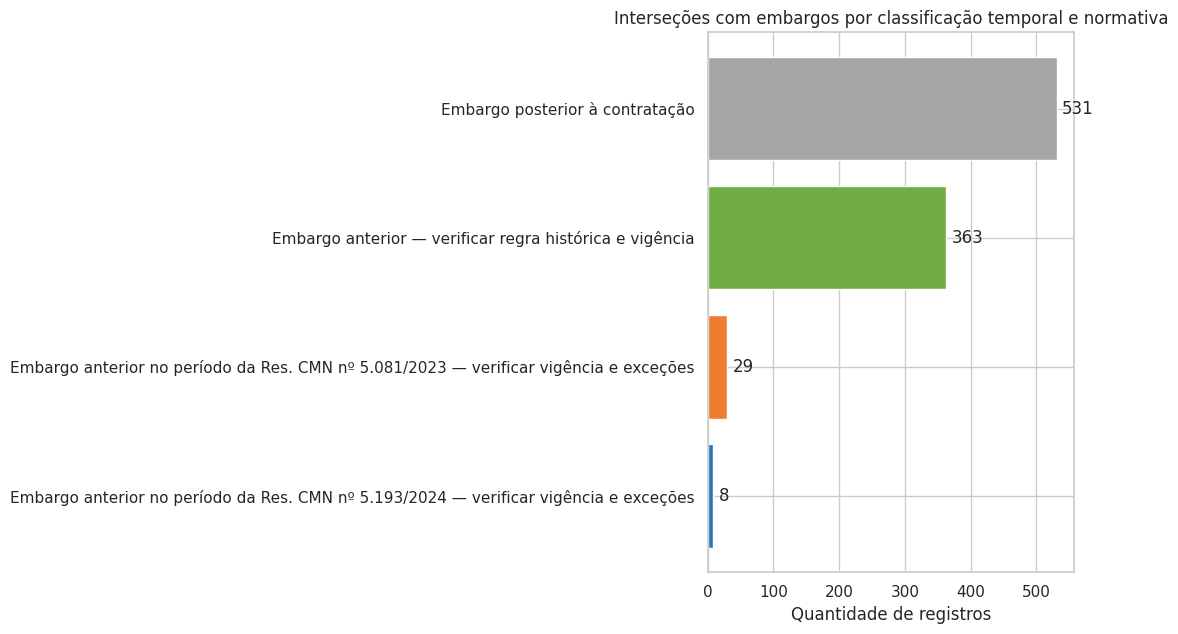

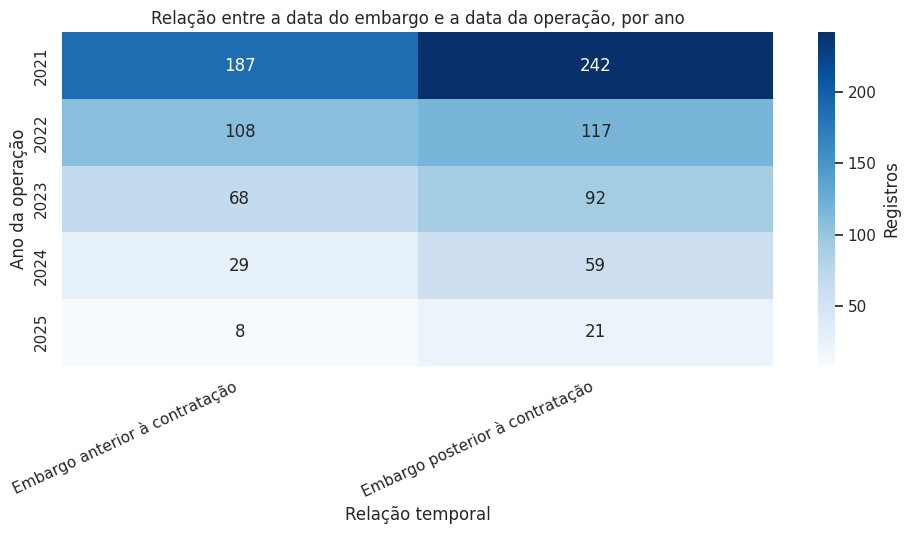

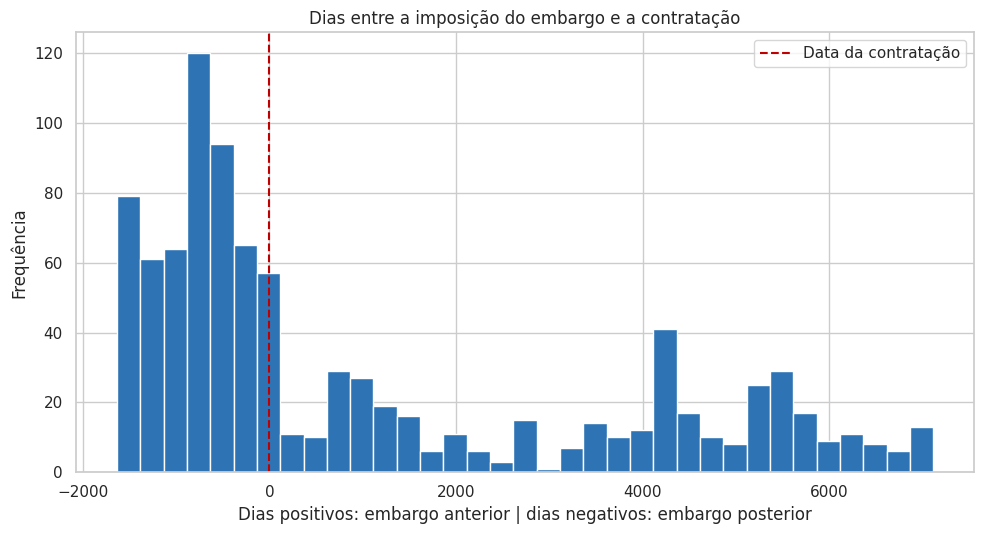

In [10]:
# ============================================================
# 10. GERAR GRÁFICOS
# ============================================================

cores = ['#2E74B5', '#ED7D31', '#70AD47', '#A5A5A5', '#8064A2']

# Gráfico 1 — registros por classificação
grafico = resumo_classificacao.sort_values('QUANTIDADE_REGISTROS')
fig, ax = plt.subplots(figsize=(11, 6.5))
barras = ax.barh(grafico['_CLASSIFICACAO_DISSERTACAO'], grafico['QUANTIDADE_REGISTROS'], color=cores[:len(grafico)])
ax.bar_label(barras, padding=4, fmt='%.0f')
ax.set_title('Interseções com embargos por classificação temporal e normativa')
ax.set_xlabel('Quantidade de registros')
ax.set_ylabel('')
plt.tight_layout()
caminho_g1 = PASTA_GRAFICOS / '01_registros_por_classificacao.png'
fig.savefig(caminho_g1, dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)

# Gráfico 2 — matriz ano da operação × relação temporal
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(matriz_ano_relacao, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': 'Registros'}, ax=ax)
ax.set_title('Relação entre a data do embargo e a data da operação, por ano')
ax.set_xlabel('Relação temporal')
ax.set_ylabel('Ano da operação')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
caminho_g2 = PASTA_GRAFICOS / '02_matriz_ano_relacao.png'
fig.savefig(caminho_g2, dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)

# Gráfico 3 — distância temporal; percentis reduzem o efeito de valores extremos na visualização
intervalos = dados['_DIAS_ENTRE_EMBARGO_E_OPERACAO'].dropna()
if not intervalos.empty:
    limite_inf, limite_sup = intervalos.quantile([0.01, 0.99])
    intervalo_plot = intervalos.clip(limite_inf, limite_sup)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.hist(intervalo_plot, bins=35, color='#2E74B5', edgecolor='white')
    ax.axvline(0, color='#C00000', linestyle='--', linewidth=1.5, label='Data da contratação')
    ax.set_title('Dias entre a imposição do embargo e a contratação')
    ax.set_xlabel('Dias positivos: embargo anterior | dias negativos: embargo posterior')
    ax.set_ylabel('Frequência')
    ax.legend()
    plt.tight_layout()
    caminho_g3 = PASTA_GRAFICOS / '03_dias_entre_embargo_e_operacao.png'
    fig.savefig(caminho_g3, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)
else:
    caminho_g3 = None


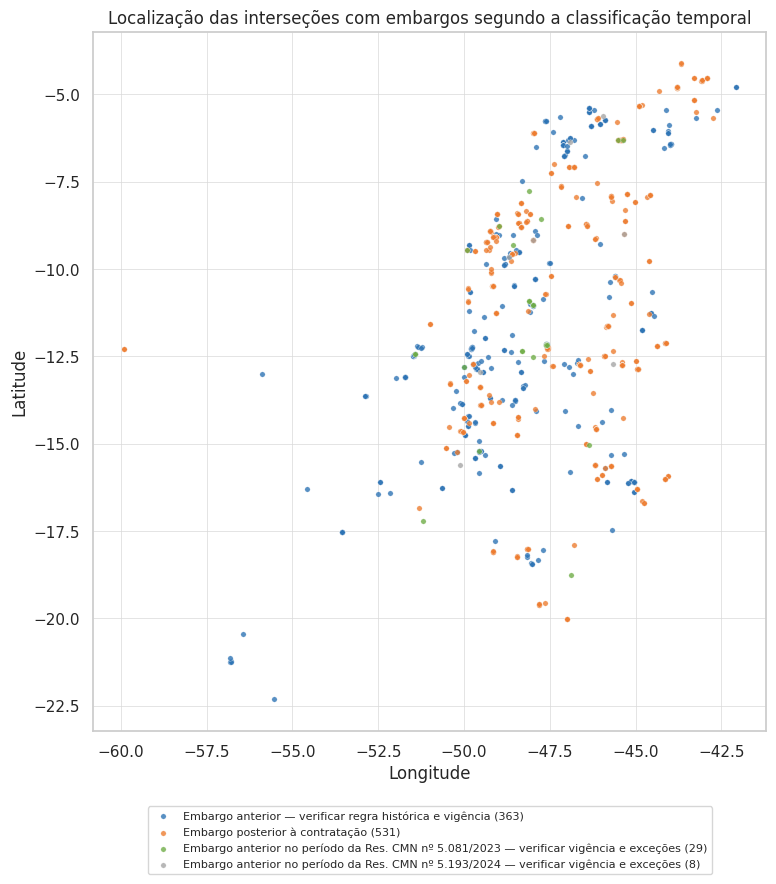

Geometrias válidas no mapa: 931


In [11]:
# ============================================================
# 11. GERAR MAPA DA CLASSIFICAÇÃO TEMPORAL
# ============================================================

caminho_mapa = None
coluna_geom = CAMPOS['GEOMETRIA_INTERSECAO']
if coluna_geom:
    geometrias = dados[coluna_geom].map(corrigir_geometria)
    mascara = geometrias.notna()
    gdf = gpd.GeoDataFrame(
        dados.loc[mascara, ['_CLASSIFICACAO_DISSERTACAO', '_ID_LINHA_ORIGINAL']].copy(),
        geometry=geometrias.loc[mascara], crs='EPSG:4326',
    )
    if not gdf.empty:
        categorias = list(gdf['_CLASSIFICACAO_DISSERTACAO'].dropna().unique())
        paleta = dict(zip(categorias, ['#2E74B5', '#ED7D31', '#70AD47', '#A5A5A5', '#8064A2'][:len(categorias)]))
        # Polígonos de interseção são muito pequenos na escala do Cerrado.
        # Pontos representativos tornam a distribuição legível sem alterar a classificação.
        pontos = gdf.to_crs('EPSG:5880')
        pontos = gpd.GeoDataFrame(
            pontos.drop(columns='geometry'),
            geometry=pontos.geometry.representative_point(),
            crs='EPSG:5880',
        ).to_crs('EPSG:4326')

        fig, ax = plt.subplots(figsize=(10, 9))
        for categoria in categorias:
            parte = pontos[pontos['_CLASSIFICACAO_DISSERTACAO'].eq(categoria)]
            parte.plot(
                ax=ax, color=paleta[categoria], marker='o', markersize=15,
                edgecolor='white', linewidth=0.25, alpha=0.80,
                label=f'{categoria} ({len(parte):,})'
            )
        xmin, ymin, xmax, ymax = pontos.total_bounds
        margem_x = max((xmax - xmin) * 0.05, 0.5)
        margem_y = max((ymax - ymin) * 0.05, 0.5)
        ax.set_xlim(xmin - margem_x, xmax + margem_x)
        ax.set_ylim(ymin - margem_y, ymax + margem_y)
        ax.set_title('Localização das interseções com embargos segundo a classificação temporal')
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')
        ax.grid(True, color='#D9D9D9', linewidth=0.5)
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), fontsize=8, frameon=True)
        plt.tight_layout()
        caminho_mapa = PASTA_MAPAS / '01_mapa_classificacao_temporal.png'
        fig.savefig(caminho_mapa, dpi=220, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        print('Geometrias válidas no mapa:', f'{len(gdf):,}')
if caminho_mapa is None:
    print('Mapa não gerado: coluna WKT ausente ou sem geometrias válidas.')


In [12]:
# ============================================================
# 12. GERAR RELATÓRIO WORD DA ANÁLISE TEMPORAL
# ============================================================

def configurar_documento(doc):
    secao = doc.sections[0]
    secao.page_width, secao.page_height = Cm(21), Cm(29.7)
    secao.top_margin, secao.left_margin = Cm(3), Cm(3)
    secao.right_margin, secao.bottom_margin = Cm(2), Cm(2)
    estilo = doc.styles['Normal']
    estilo.font.name = 'Times New Roman'
    estilo._element.rPr.rFonts.set(qn('w:eastAsia'), 'Times New Roman')
    estilo.font.size = Pt(12)
    estilo.paragraph_format.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY
    estilo.paragraph_format.line_spacing = 1.5
    estilo.paragraph_format.first_line_indent = Cm(1.25)
    for nome in ['Heading 1', 'Heading 2']:
        e = doc.styles[nome]
        e.font.name = 'Times New Roman'
        e._element.rPr.rFonts.set(qn('w:eastAsia'), 'Times New Roman')
        e.font.size = Pt(12)
        e.font.bold = True

def adicionar_tabela(doc, df, max_linhas=25):
    tabela_df = df.head(max_linhas).copy()
    tabela = doc.add_table(rows=1, cols=len(tabela_df.columns))
    tabela.alignment = WD_TABLE_ALIGNMENT.CENTER
    tabela.style = 'Table Grid'
    for j, coluna in enumerate(tabela_df.columns):
        p = tabela.rows[0].cells[j].paragraphs[0]
        p.paragraph_format.first_line_indent = Cm(0)
        r = p.add_run(str(coluna).replace('_', ' '))
        r.bold = True
        r.font.name = 'Times New Roman'
        r.font.size = Pt(8)
    for _, linha in tabela_df.iterrows():
        celulas = tabela.add_row().cells
        for j, valor in enumerate(linha):
            celulas[j].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
            p = celulas[j].paragraphs[0]
            p.paragraph_format.first_line_indent = Cm(0)
            r = p.add_run('' if pd.isna(valor) else str(valor))
            r.font.name = 'Times New Roman'
            r.font.size = Pt(8)
    return tabela

total = len(dados)
n_posteriores = int(dados['_RELACAO_TEMPORAL'].eq('Embargo posterior à contratação').sum())
n_anteriores = int(embargo_ja_existia.sum())
n_anteriores_2024_25 = int((embargo_ja_existia & (data_operacao >= DATA_INICIO_RES_5081)).sum())
n_indeterminados = int(dados['_RELACAO_TEMPORAL'].eq('Situação temporal indeterminada').sum())

doc = Document()
configurar_documento(doc)
doc.add_heading('Análise temporal das interseções com embargos ambientais federais', level=1)
p = doc.add_paragraph()
p.add_run('Período das operações: 2021–2025. ').bold = True
p.add_run('Unidade principal: todas as linhas da base expandida da versão 2, sem deduplicação.')

doc.add_heading('1 Síntese dos resultados', level=2)
doc.add_paragraph(
    f'Foram analisados {total:,} registros espaciais. Em {n_anteriores:,} registros, a data do embargo '
    f'era anterior ou igual à data da contratação; em {n_posteriores:,}, o embargo foi imposto depois da operação; '
    f'e {n_indeterminados:,} permaneceram temporalmente indeterminados.'
)
doc.add_paragraph(
    f'Entre as operações contratadas a partir de 2 de janeiro de 2024, {n_anteriores_2024_25:,} registros apresentaram '
    'embargo anterior ou na mesma data. Esses casos constituem prioridade para verificação, mas a base não permite '
    'confirmar automaticamente a vigência, as exceções normativas ou a identidade do responsável.'
)
doc.add_paragraph(
    'Os valores financeiros do relatório correspondem à soma dos valores presentes nas linhas expandidas. Não devem '
    'ser interpretados como volume único contratado nem como montante proporcional aplicado na área de interseção.'
)

doc.add_heading('2 Classificação temporal e normativa', level=2)
adicionar_tabela(doc, resumo_classificacao.rename(columns={
    '_CLASSIFICACAO_DISSERTACAO': 'CLASSIFICAÇÃO',
    'QUANTIDADE_REGISTROS': 'REGISTROS',
    'QUANTIDADE_GLEBAS_DISTINTAS': 'GLEBAS',
    'QUANTIDADE_EMBARGOS_DISTINTOS': 'EMBARGOS',
    'QUANTIDADE_REF_BACEN_DISTINTOS': 'REF BACEN',
    'AREA_INTERSECAO_ACUMULADA_HA': 'ÁREA ACUMULADA (HA)',
    'VALOR_SOMADO_NAS_LINHAS_R': 'VALOR NAS LINHAS (R$)',
}))

doc.add_paragraph(
    'Nota: “embargo anterior” não significa, por si só, operação irregular. A confirmação depende da situação do '
    'embargo na contratação, da norma vigente, da localização, da relação com o beneficiário e das exceções aplicáveis.'
)

doc.add_heading('3 Figuras', level=2)
for titulo, caminho in [
    ('Figura 1 – Registros por classificação temporal e normativa', caminho_g1),
    ('Figura 2 – Relação temporal por ano da operação', caminho_g2),
    ('Figura 3 – Distribuição dos dias entre embargo e contratação', caminho_g3),
    ('Figura 4 – Distribuição espacial das classificações', caminho_mapa),
]:
    if caminho is not None and Path(caminho).exists():
        p = doc.add_paragraph(titulo)
        p.paragraph_format.first_line_indent = Cm(0)
        doc.add_picture(str(caminho), width=Cm(15.5))
        fonte = doc.add_paragraph('Fonte: elaborado pelo autor com base nos dados do SICOR e do Ibama.')
        fonte.paragraph_format.first_line_indent = Cm(0)

doc.add_heading('4 Limitações', level=2)
doc.add_paragraph(
    'A base não apresentou campo inequivocamente documentado de baixa, suspensão ou desembargo. Campos de última '
    'alteração não foram usados como data de encerramento. O campo EMB_SIT_DESMAT também não foi interpretado como '
    'situação jurídica por ausência de dicionário seguro. Por isso, embargo anterior à contratação foi classificado '
    'como ocorrência que requer análise documental, e não como violação comprovada.'
)

ARQUIVO_WORD = PASTA_SAIDA / 'relatorio_analise_temporal_embargos.docx'
doc.save(ARQUIVO_WORD)
print('Relatório Word:', ARQUIVO_WORD)


Relatório Word: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/embargos/resultados_por_id_gleba2/analise_temporal_embargos/relatorio_analise_temporal_embargos.docx


In [13]:
# ============================================================
# 13. VALIDAR E LISTAR OS PRODUTOS
# ============================================================

assert len(dados) == len(dados_brutos), 'A quantidade de linhas foi alterada.'
assert dados['_ID_LINHA_ORIGINAL'].is_unique, 'O identificador de linha não é único.'
assert resumo_classificacao['QUANTIDADE_REGISTROS'].sum() == len(dados), 'A classificação não reconcilia com a base.'
assert dados['_DATA_OPERACAO'].notna().sum() + dados['_DATA_OPERACAO'].isna().sum() == len(dados)
assert dados['_DATA_EMBARGO'].notna().sum() + dados['_DATA_EMBARGO'].isna().sum() == len(dados)

manifesto = []
for caminho in sorted(PASTA_SAIDA.rglob('*')):
    if caminho.is_file():
        manifesto.append({
            'ARQUIVO': str(caminho.relative_to(PASTA_SAIDA)),
            'TAMANHO_BYTES': caminho.stat().st_size,
        })
manifesto = pd.DataFrame(manifesto)
salvar_csv(manifesto, PASTA_SAIDA / 'manifesto_produtos.csv')

print('\nVALIDAÇÃO CONCLUÍDA')
print('Linhas preservadas:', f'{len(dados):,}')
print('Glebas distintas:', f"{dados['_ID_GLEBA2'].nunique():,}")
print('Embargos distintos:', f"{dados['_ID_EMBARGO'].nunique():,}")
print('Embargos anteriores ou na mesma data:', f'{int(embargo_ja_existia.sum()):,}')
print('Embargos posteriores:', f"{int(dados['_RELACAO_TEMPORAL'].eq('Embargo posterior à contratação').sum()):,}")
print('Pasta final:', PASTA_SAIDA)
display(manifesto)



VALIDAÇÃO CONCLUÍDA
Linhas preservadas: 931
Glebas distintas: 626
Embargos distintos: 388
Embargos anteriores ou na mesma data: 400
Embargos posteriores: 531
Pasta final: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/embargos/resultados_por_id_gleba2/analise_temporal_embargos


,ARQUIVO,TAMANHO_BYTES
0,bases_analiticas/analise_temporal_embargos_classificada.csv,17765622
1,graficos/01_registros_por_classificacao.png,144379
2,graficos/02_matriz_ano_relacao.png,151696
3,graficos/03_dias_entre_embargo_e_operacao.png,89937
4,mapas/01_mapa_classificacao_temporal.png,230318
5,relatorio_analise_temporal_embargos.docx,551021
6,tabelas/01_diagnostico_campos.csv,465
7,tabelas/02_qualidade_temporal.csv,426
8,tabelas/03_resumo_geral.csv,312
9,tabelas/04_resumo_classificacao_dissertacao.csv,652


## Como interpretar o resultado

O notebook produz três níveis de informação:

1. **Relação temporal objetiva:** informa se o embargo é anterior, contemporâneo ou posterior à contratação.
2. **Período normativo:** separa as operações anteriores a 02/01/2024, o período da Resolução CMN nº 5.081/2023 e o período da Resolução CMN nº 5.193/2024.
3. **Classificação para a dissertação:** indica quais casos podem ser afastados temporalmente e quais ainda exigem confirmação da vigência e das exceções.

Nenhuma classe criada pelo notebook deve ser denominada automaticamente “operação ilegal”. O resultado é uma triagem para análise jurídica, cadastral e documental.
